# Regression: a reversible reaction in a batch reactor

**CHME 5137, homework after Lectures 12 and 13 (October 20 and 23, 2026).** Section 5 of
the Lecture 13 notebook started this. Here it is in full.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's A ⇌ B fitting
exercise of earlier years, and checked by Prof. West.*

---

You run a reversible, first-order reaction in a batch reactor:
$$\mathrm{A} \rightleftharpoons \mathrm{B}, \qquad
\frac{dC_A}{dt} = k_r C_B - k_f C_A, \qquad C_B = C_{A,0} - C_A$$
Every run starts with $C_{A,0} = 10$ mol/L and no B. You measured $C_A$ every 10 s for
100 s, at three temperatures.

**Kinetics.** The forward rate constant follows the Arrhenius expression,
$k_f = A \exp(-E_a/RT)$.

**Thermodynamics.** At equilibrium the forward and reverse rates are equal, so the
equilibrium constant is $K = k_f/k_r$. (Assume an ideal solution, so this
concentration-based $K$ is the thermodynamic one.) From thermodynamics,
$$\Delta G^\circ = -RT\ln K \qquad\text{and}\qquad \Delta G^\circ = \Delta H - T\,\Delta S$$
A and B have very similar heat capacities, so take $\Delta H$ and $\Delta S$ to be
independent of temperature. Then $k_r = k_f/K$, and the whole model has **four
parameters**: $\log_{10} A$, $E_a$, $\Delta H$ and $\Delta S$.

Before the experiments, from the literature and a quantum chemistry calculation, your
estimates were $\log_{10}A \approx 6$ (A in s⁻¹), $E_a \approx 45$ kJ/mol,
$\Delta H \approx -10$ kJ/mol and $\Delta S \approx -50$ J/mol/K. Let's see what the data say.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then commit
  with a message that says what you did, and push. At least one commit per task.
  **Commit the `.ipynb` and its paired `.py` together.**
- **Answer the questions in words**, in the markdown cells marked *Answer*.
- **Say what your ± means.** One standard error, or a 95% interval? Either is fine. Say which (Lecture 13).
- **Let bugs shout.** If `solve_ivp` fails, `raise` an error with its `message`.
  Don't let a half-finished solution reach `curve_fit` without anyone noticing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate
import scipy.optimize
import scipy.stats

plt.rcParams['figure.figsize'] = [5, 3]
R = 8.314  # J/mol/K

The data, the same as in class:

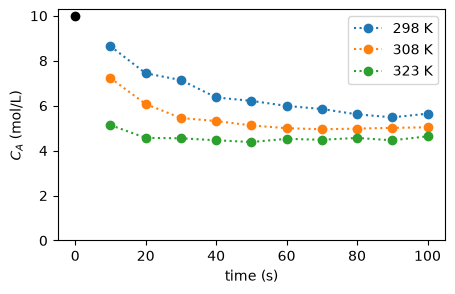

In [2]:
cA0 = 10.0   # mol/L
times = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100.])   # s
cA_data = {   # mol/L, keyed by temperature in K
    298.15: np.array([8.649, 7.441, 7.141, 6.366, 6.215, 5.990, 5.852, 5.615, 5.481, 5.644]),
    308.15: np.array([7.230, 6.073, 5.452, 5.317, 5.121, 4.998, 4.951, 4.978, 5.015, 5.036]),
    323.15: np.array([5.137, 4.568, 4.548, 4.461, 4.382, 4.525, 4.483, 4.565, 4.459, 4.635]),
}
temperatures = np.array(list(cA_data))

for T, cA in cA_data.items():
    plt.plot(times, cA, 'o:', label=f'{T:.0f} K')
plt.plot(0, cA0, 'ko')
plt.xlabel('time (s)')
plt.ylabel('$C_A$ (mol/L)')
plt.ylim(0, None)
plt.legend()
plt.show()

## 1. One temperature

**(a) The model.** Write `cA_model(times, kf, kr)`, which solves the ODE with
`scipy.integrate.solve_ivp` and returns $C_A$ at `times` (use `t_eval`). In Lecture 13 we fitted
functions that were a formula. `curve_fit` doesn't care: any function that takes the
independent variable first and then the parameters, and returns predictions, will do. Even
one that runs a whole simulation.

Then **test it** (Lecture 11). This ODE has an exact solution,
$$C_A(t) = C_{A,\mathrm{eq}} + (C_{A,0} - C_{A,\mathrm{eq}})\,e^{-(k_f+k_r)t},
\qquad C_{A,\mathrm{eq}} = C_{A,0}\frac{k_r}{k_f+k_r}$$
Check that your function agrees with it, for some reasonable $k_f$ and $k_r$, with an
`assert`. (We use `solve_ivp` anyway because your project's model won't have an exact
solution.)

In [3]:
def cA_model(times, kf, kr):
    """C_A (mol/L) at each of `times` (s), for rate constants kf and kr (1/s)."""
    def rhs(t, y):
        cA = y[0]
        cB = cA0 - cA                     # FILL IN: C_B from C_A
        return [kr * cB - kf * cA]                 # FILL IN: dC_A/dt
    sol = scipy.integrate.solve_ivp(rhs, (0, times[-1]), [cA0], t_eval=times,
                                    rtol=1e-8, atol=1e-10)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.y[0]


def cA_exact(times, kf, kr):
    """The exact solution, for testing cA_model."""
    cA_eq = cA0 * kr / (kf + kr)                      # FILL IN
    return cA_eq + (cA0 - cA_eq) * np.exp(-(kf + kr) * times)                       # FILL IN


kf_test, kr_test = 0.02, 0.03
assert np.allclose(cA_model(times, kf_test, kr_test),
                   cA_exact(times, kf_test, kr_test), rtol=1e-6)
print("cA_model agrees with the exact solution")


cA_model agrees with the exact solution


**(b) Fit it at 298.15 K**, with `scipy.optimize.curve_fit`. **Try it without `p0` first.**
It may fail with an error from deep inside SciPy, or it may appear to succeed. Either way,
find out what happened: print and plot what came back, or what `cA_model` returns
at `curve_fit`'s default starting point. Then give it a starting guess you can justify
from the data. Roughly how long does $C_A$ take to get halfway to where it ends up?

In [4]:
cA_298 = cA_data[298.15]

try:
    popt, pcov = scipy.optimize.curve_fit(cA_model, times, cA_298)
    print("curve_fit returned kf, kr =", popt)
    print("pcov =", pcov)
except Exception as e:
    print("curve_fit failed:", type(e).__name__, e)

curve_fit failed: RuntimeError Required step size is less than spacing between numbers.


/home/kamal.ka/venvs/chme5137/lib/python3.12/site-packages/scipy/integrate/_ivp/rk.py:63: RuntimeWarning: overflow encountered in dot
  dy = np.dot(K[:s].T, a[:s]) * h
/home/kamal.ka/venvs/chme5137/lib/python3.12/site-packages/scipy/integrate/_ivp/rk.py:106: RuntimeWarning: invalid value encountered in dot
  return np.dot(K.T, self.E) * h


In [5]:
tried = []

def cA_model_logged(times, kf, kr):
    tried.append((kf, kr))
    return cA_model(times, kf, kr)

try:
    scipy.optimize.curve_fit(cA_model_logged, times, cA_298)
except RuntimeError as e:
    print("failed:", e)

for kf, kr in tried:
    print(f"kf = {kf:12.6g}   kr = {kr:12.6g}")

failed: Required step size is less than spacing between numbers.
kf =            1   kr =            1
kf =            1   kr =            1
kf =            1   kr =            1
kf =      -99.288   kr =      -98.712


[5.00000001 4.99999997 5.         4.99999999 5.00000001 5.00000001
 5.00000002 5.00000002 5.00000002 5.00000002]


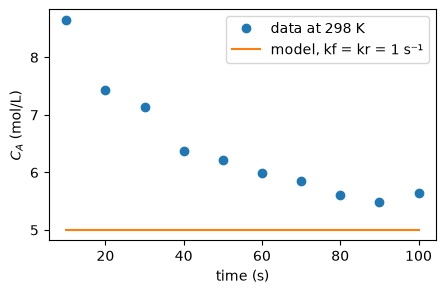

In [6]:
print(cA_model(times, 1.0, 1.0))

plt.plot(times, cA_298, 'o', label='data at 298 K')
plt.plot(times, cA_model(times, 1.0, 1.0), '-', label='model, kf = kr = 1 s⁻¹')
plt.xlabel('time (s)')
plt.ylabel('$C_A$ (mol/L)')
plt.legend()
plt.show()

**(c) Look at it.** Plot the data and the fitted curve, and below it the residuals
(data minus model). Report $k_f$ and $k_r$ with their uncertainties.

What happened without `p0`, and why? What starting guess did you use, and how did you
choose it?

In [7]:
# Starting guess from the 298 K data:
cA_plateau = cA_298[-4:].mean()          # last four points, about 5.55 mol/L
cA_half = (cA0 + cA_plateau) / 2         # halfway from 10 to the plateau, about 7.8 mol/L
t_half = 17.0                            # s, read off the plot: data crosses 7.8 between 10 s and 20 s

k_sum = np.log(2) / t_half               # kf + kr, from the exact solution
kr_guess = k_sum * cA_plateau / cA0      # from C_A,eq / C_A,0 = kr / (kf + kr)
kf_guess = k_sum - kr_guess
print(f"guess: kf = {kf_guess:.4f}, kr = {kr_guess:.4f} 1/s")

popt, pcov = scipy.optimize.curve_fit(cA_model, times, cA_298, p0=[kf_guess, kr_guess])
kf_fit, kr_fit = popt
perr = np.sqrt(np.diag(pcov))
print(f"kf = {kf_fit:.4f} ± {perr[0]:.4f} 1/s")
print(f"kr = {kr_fit:.4f} ± {perr[1]:.4f} 1/s")

guess: kf = 0.0177, kr = 0.0230 1/s
kf = 0.0168 ± 0.0008 1/s
kr = 0.0201 ± 0.0015 1/s


*Answer:*

Without p0, curve_fit starts at kf = kr = 1 s⁻¹, so the model is already at equilibrium (flat at 5.0 mol/L) before the first data point, and changing kf or kr barely changes it. With no slope to follow, curve_fit jumped to kf ≈ kr ≈ −99 s⁻¹, where C_A grows exponentially, and solve_ivp failed.

For the starting guess, I took the plateau (≈ 5.55 mol/L) to give kr/(kf + kr) and the half-time (≈ 17 s) to give kf + kr = ln 2/t½, which gave kf = 0.0177 and kr = 0.0230 s⁻¹. The fit gives kf = 0.0168 ± 0.0008 s⁻¹ and kr = 0.0201 ± 0.0015 s⁻¹ (± is one standard error). The residuals scatter randomly within about ±0.2 mol/L, so the model fits well.

## 2. Three temperatures, in two steps

**(a)** Fit $k_f$ and $k_r$ separately at each temperature, and make a small table of
$k_f$, $k_r$ (each with its ±) and $K = k_f/k_r$.

**Before fitting anything else:** from your $K$ values alone, is the reaction endothermic
or exothermic? How can you tell?

In [8]:
kf_T, kr_T, kf_err, kr_err = [], [], [], []
for T in temperatures:
    popt, pcov = scipy.optimize.curve_fit(cA_model, times, cA_data[T], p0=[kf_fit, kr_fit])
    perr = np.sqrt(np.diag(pcov))
    kf_T.append(popt[0]); kr_T.append(popt[1])
    kf_err.append(perr[0]); kr_err.append(perr[1])

kf_T, kr_T = np.array(kf_T), np.array(kr_T)
kf_err, kr_err = np.array(kf_err), np.array(kr_err)
K_T = kf_T / kr_T

print("  T (K)        kf (1/s)              kr (1/s)           K")
for T, kf, dkf, kr, dkr, K in zip(temperatures, kf_T, kf_err, kr_T, kr_err, K_T):
    print(f"{T:7.2f}   {kf:.4f} ± {dkf:.4f}   {kr:.4f} ± {dkr:.4f}   {K:.3f}")

  T (K)        kf (1/s)              kr (1/s)           K
 298.15   0.0168 ± 0.0008   0.0201 ± 0.0015   0.837
 308.15   0.0393 ± 0.0009   0.0392 ± 0.0011   1.000
 323.15   0.1189 ± 0.0064   0.0975 ± 0.0056   1.220


**(b) Arrhenius.** As in Lecture 13: `scipy.stats.linregress` on $\ln k_f$ against
$1/T$ gives $E_a$ from the slope and $\ln A$ from the intercept. Convert $\ln A$ to
$\log_{10} A$.

**(c) van 't Hoff.** Put the two expressions for $\Delta G^\circ$ together and divide by $-RT$:
$$\ln K = -\frac{\Delta H}{R}\,\frac{1}{T} + \frac{\Delta S}{R}$$
So $\ln K$ against $1/T$ is a straight line too, with slope $-\Delta H/R$ and intercept
$\Delta S/R$. Fit it, and get $\Delta H$ and $\Delta S$, with their ±. Does the sign of
$\Delta H$ agree with what you said in (a)?

Ea = 62.6 ± 1.0 kJ/mol,  log10 A = 9.20 ± 0.17
dH = 12.0 ± 0.7 kJ/mol,  dS = 38.8 ± 2.4 J/mol/K


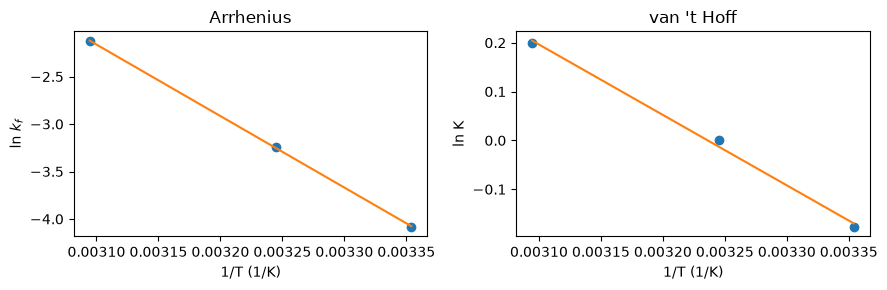

In [9]:
inv_T = 1 / temperatures

arr = scipy.stats.linregress(inv_T, np.log(kf_T))
Ea = -arr.slope * R / 1000                    # kJ/mol
Ea_err = arr.stderr * R / 1000
log10A = arr.intercept / np.log(10)
log10A_err = arr.intercept_stderr / np.log(10)
print(f"Ea = {Ea:.1f} ± {Ea_err:.1f} kJ/mol,  log10 A = {log10A:.2f} ± {log10A_err:.2f}")

vh = scipy.stats.linregress(inv_T, np.log(K_T))
dH = -vh.slope * R / 1000                     # kJ/mol
dH_err = vh.stderr * R / 1000
dS = vh.intercept * R                         # J/mol/K
dS_err = vh.intercept_stderr * R
print(f"dH = {dH:.1f} ± {dH_err:.1f} kJ/mol,  dS = {dS:.1f} ± {dS_err:.1f} J/mol/K")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))
ax1.plot(inv_T, np.log(kf_T), 'o')
ax1.plot(inv_T, arr.intercept + arr.slope * inv_T, '-')
ax1.set_xlabel('1/T (1/K)'); ax1.set_ylabel('ln $k_f$'); ax1.set_title('Arrhenius')
ax2.plot(inv_T, np.log(K_T), 'o')
ax2.plot(inv_T, vh.intercept + vh.slope * inv_T, '-')
ax2.set_xlabel('1/T (1/K)'); ax2.set_ylabel('ln K'); ax2.set_title("van 't Hoff")
plt.tight_layout()
plt.show()

**(d)** `linregress` gave you a ± on each of these. What does that ± know about,
and what has it left out? Think about how many points each straight line had, and about
the ± you got in (a).

*Answer

K rises with temperature (0.84 → 1.00 → 1.22), so heating pushes the equilibrium towards B, and by Le Chatelier the reaction is endothermic. The van ‘t Hoff fit agrees: ΔH = +12.0 ± 0.7 kJ/mol, with ΔS = +38.8 ± 2.4 J/mol/K. Arrhenius gives Ea = 62.6 ± 1.0 kJ/mol and log₁₀A = 9.20 ± 0.17. All ± are one standard error from linregress. All four differ from the pre-experiment estimates; even the sign of ΔH is the opposite.

The linregress ± only knows how far three points scatter about a straight line. That leaves 3 − 2 = 1 degree of freedom, so the scatter estimate itself is very unreliable. It also leaves out the ± on each k_f and K from (a): linregress treats those three points as exact, so the uncertainty in the 30 original measurements never reaches Ea, ΔH or ΔS.


## 3. All the data at once

Step 2 fitted 3 × 2 rate constants, then fitted lines through three points each. Better:
fit the four parameters you actually want **directly to all 30 measurements**, so that
every measurement counts and the uncertainties carry all the way through.

`curve_fit` wants one `xdata` and one `ydata`. With several experiments, stack them:
`ydata` is all 30 concentrations in one array, and `xdata` carries **both** the
temperature and the time of each one. `curve_fit` never looks inside `xdata`; it just passes it
to your function. So it can be a tuple of two arrays:

In [10]:
T_all = np.repeat(temperatures, len(times))     # 298.15 ten times, then 308.15 ten times, ...
t_all = np.tile(times, len(temperatures))        # 10, 20, ..., 100, three times over
cA_all = np.concatenate([cA_data[T] for T in temperatures])
x_all = (T_all, t_all)
print(T_all[:12], t_all[:12], cA_all[:12], sep='\n')

[298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15
 308.15 308.15]
[ 10.  20.  30.  40.  50.  60.  70.  80.  90. 100.  10.  20.]
[8.649 7.441 7.141 6.366 6.215 5.99  5.852 5.615 5.481 5.644 7.23  6.073]


**(a)** Write `cA_model_all(x, log10A, Ea, dH, dS)`. Unpack `x` into temperatures and
times. For each temperature, work out $k_f$, $K$ and $k_r$, then call your `cA_model` for
that temperature's times, and put the results in the right places of the output array.
Solve one ODE per temperature, not one per data point. A boolean mask such as
`T_col == T` picks out the rows.

Notice the **units**: $E_a$ and $\Delta H$ in kJ/mol, $\Delta S$ in J/mol/K, and $A$ as
$\log_{10}A$. That keeps all four parameters between about 1 and 100. An optimizer
has an easier time when its parameters are all a similar size than when one is
$10^{9}$ and another is $10^{-2}$. So convert carefully inside the function.

Then fit it, **starting from your answers to task 2**, and report the four parameters with
their ±.

In [11]:
def cA_model_all(x, log10A, Ea, dH, dS):
    """C_A (mol/L) for every (T, t) pair in x. Ea and dH in kJ/mol, dS in J/mol/K."""
    T_col, t_col = x
    cA_out = np.zeros(len(t_col))
    for T in np.unique(T_col):
        rows = (T_col == T)
        kf = 10**log10A * np.exp(-Ea * 1000 / (R * T))      # kJ → J
        K = np.exp(-(dH * 1000 - T * dS) / (R * T))         # ΔG° = ΔH − TΔS = −RT ln K
        kr = kf / K
        cA_out[rows] = cA_model(t_col[rows], kf, kr)
    return cA_out

In [12]:
p0_task2 = [log10A, Ea, dH, dS]
popt_all, pcov_all = scipy.optimize.curve_fit(cA_model_all, x_all, cA_all, p0=p0_task2)
perr_all = np.sqrt(np.diag(pcov_all))

names = ['log10 A', 'Ea (kJ/mol)', 'dH (kJ/mol)', 'dS (J/mol/K)']
for name, value, err in zip(names, popt_all, perr_all):
    print(f"{name:14s} = {value:7.2f} ± {err:.2f}")

log10 A        =    9.49 ± 0.37
Ea (kJ/mol)    =   64.31 ± 2.14
dH (kJ/mol)    =   11.53 ± 0.79
dS (J/mol/K)   =   37.35 ± 2.51


**(b)** Now start from your estimates from before the experiments instead (6, 45, −10, −50).
Does it find the same answer? How far did the data move you from what you expected?

In [13]:
popt_prior, pcov_prior = scipy.optimize.curve_fit(cA_model_all, x_all, cA_all, p0=[6, 45, -10, -50])
for name, value, err in zip(names, popt_prior, np.sqrt(np.diag(pcov_prior))):
    print(f"{name:14s} = {value:7.2f} ± {err:.2f}")

log10 A        =    9.49 ± 0.37
Ea (kJ/mol)    =   64.31 ± 2.14
dH (kJ/mol)    =   11.53 ± 0.79
dS (J/mol/K)   =   37.35 ± 2.51


**(c)** Compare with task 2. Are the centres the same? Are the error bars? Which set of
error bars would you believe, and why?

**(d) The correlation matrix.** The off-diagonal elements of `pcov` say how the errors in
the parameters go together (Lecture 13). Turn the covariance into correlations:
`pcov / np.outer(perr, perr)`. Which pairs are strongly correlated? Why those pairs?
(Think about Lecture 13's ridge, and about the range of temperatures you measured over.)
If someone quotes only your four ± values, what are they missing?

In [14]:
corr = pcov_all / np.outer(perr_all, perr_all)
np.set_printoptions(precision=4, suppress=True)
print(names)
print(corr)

['log10 A', 'Ea (kJ/mol)', 'dH (kJ/mol)', 'dS (J/mol/K)']
[[ 1.      0.9997 -0.3627 -0.3653]
 [ 0.9997  1.     -0.3734 -0.3757]
 [-0.3627 -0.3734  1.      0.9996]
 [-0.3653 -0.3757  0.9996  1.    ]]


(b) Starting from the pre-experiment estimates (6, 45, −10, −50), the fit finds the same answer. The data moved us a long way: log₁₀A from 6 to 9.5, Ea from 45 to 64 kJ/mol, and ΔH and ΔS both changed sign (ΔH from −10 to +11.5 kJ/mol, ΔS from −50 to +37 J/mol/K).

(c) The centres are close to task 2, but the error bar on Ea doubles (±2.1 vs ±1.0 kJ/mol), and log₁₀A’s goes from ±0.17 to ±0.37. I’d believe the global fit’s: it uses all 30 measurements, with 30 − 4 = 26 degrees of freedom, so it estimates the noise properly and carries it through to the parameters. The task 2 error bars came from the scatter of three points about a line, with 1 degree of freedom, and ignored the uncertainty in each k.

(d) log₁₀A and Ea are correlated at +0.9996, and so are ΔH and ΔS. All four were measured over only 298 to 323 K, a narrow range of 1/T, so each pair is the slope and intercept of a line fitted far from 1/T = 0. Steepening the slope while raising the intercept fits the data almost equally well, which is the ridge from Lecture 13. Someone quoting only the four ± values would miss this: the individual uncertainties are wide, but the combinations, such as k_f at 310 K, are known much more precisely.

## 4. Look at the residuals

**Always look at the residuals** (Lecture 13). Plot the residuals of the task 3 fit against
time, one colour per temperature, with a line at zero.

- Do you see a pattern, or does it look like noise?
- Is the scatter about the same width at all three temperatures? Least squares assumed it is.
- Nobody told you the measurement uncertainty, so `curve_fit` (with
  `absolute_sigma=False`, the default) estimated it from the scatter of the residuals.
  Work out that estimate yourself:
  $s = \sqrt{\sum_i r_i^2 / (N - p)}$, with $N$ data points and $p$ parameters. What does
  it say about how precisely $C_A$ was measured?
- Suppose the experimentalist now tells you their instrument is good to ±0.01 mol/L.
  What would that tell you about your model, or about the experiment?

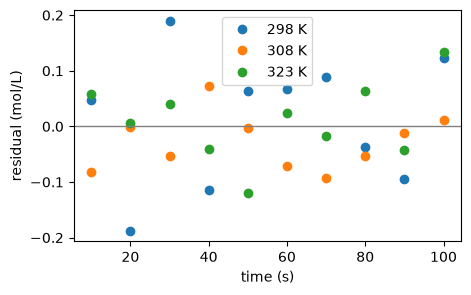

298 K: rms residual = 0.113 mol/L
308 K: rms residual = 0.056 mol/L
323 K: rms residual = 0.068 mol/L
s = 0.089 mol/L  (N = 30, p = 4)


In [15]:
residuals_all = cA_all - cA_model_all(x_all, *popt_all)

for T in temperatures:
    rows = (T_all == T)
    plt.plot(t_all[rows], residuals_all[rows], 'o', label=f'{T:.0f} K')
plt.axhline(0, color='gray', lw=1)
plt.xlabel('time (s)')
plt.ylabel('residual (mol/L)')
plt.legend()
plt.show()

for T in temperatures:
    rows = (T_all == T)
    print(f"{T:.0f} K: rms residual = {np.sqrt(np.mean(residuals_all[rows]**2)):.3f} mol/L")

N, p = len(cA_all), len(popt_all)
s = np.sqrt(np.sum(residuals_all**2) / (N - p))
print(f"s = {s:.3f} mol/L  (N = {N}, p = {p})")

The residuals look mostly like noise, with no trend in time, though at 308 K most fall slightly below zero. The scatter is not quite the same at each temperature: the RMS residual is about 0.11 mol/L at 298 K, but only 0.056 and 0.068 mol/L at 308 and 323 K. Least squares assumed equal scatter, so the 298 K run probably counts for a bit more than it should. From the residuals, s = √(Σr²/(N − p)) = 0.089 mol/L with N = 30 and p = 4, so C_A was measured to about ±0.09 mol/L, roughly 1–2% of the values.

If the instrument were really good to ±0.01 mol/L, the residuals would be about 9 times larger than the measurement noise. Then the misfit couldn’t be measurement error. Either the model is missing something (the reaction isn’t exactly first-order and reversible, or ΔH, ΔS aren’t really constant), or the experiment has other errors the instrument figure doesn’t cover, such as temperature drift, timing errors or sampling. Or the ±0.01 is optimistic.

## 5. Your project

One paragraph. Which parameters in your project's model will come from fitting data, and
where will the data come from: your own simulations, the literature, a research group? What
can you say about the errors in those data? Are they the same absolute size, the same
relative size, or known point by point? And are any of your parameters likely to be
correlated, the way $E_a$ and $A$ are here?

*Answer:*

In my project the only parameter that is fitted is the backing permeability P_b, which I find with brentq so that the predicted buccal fraction matches the 51% measured. Everything else comes from the literature: D_f from Adrover et al.’s release experiments, P from Wanasathop et al.’s correlation of porcine buccal data, and saliva volume and flow from Collins and Dawes. The 51% is a mean across subjects in a clinical study, so its error is mainly between-patient variability, not measurement noise. Because it is one number fitted with one parameter, there are no residuals, and the fit cannot estimate its own uncertainty the way curve_fit did here. The permeability correlation is fitted to log P, so its errors are roughly the same relative size, a factor rather than a fixed amount. P_b will be strongly correlated with the other parameters that control how much drug reaches saliva (D_f, L and Q_s): a faster-releasing film with a better backing could give the same 51%, much like the E_a–A ridge here. Similarly, at steady state only the combination K·D_e/h sets the epithelial flux, so K, D_e and h can’t be told apart from the split alone.

## Stretch problems (optional)

**(a) Untangle the ridge.** Write $k_f$ in terms of its value at a reference temperature in
the middle of your data, say $T_\mathrm{ref} = 310$ K:
$$k_f(T) = k_\mathrm{ref}\exp\left[-\frac{E_a}{R}\left(\frac{1}{T} - \frac{1}{T_\mathrm{ref}}\right)\right]$$
It's the same model, written differently. Fit $\log_{10}k_\mathrm{ref}$, $E_a$, $\Delta H$
and $\Delta S$, and look at the correlation matrix again. What changed, and why? Can you do
the same for $\Delta H$ and $\Delta S$?

**(b) Draw the posterior.** At 298.15 K only, put $k_f$ and $k_r$ on a 2-D grid and draw
their posterior, as in Lecture 13, part 5, with a flat prior and Gaussian errors of width
$s$ from task 4. Do its 95% credible intervals (summed over the other parameter) agree with
`curve_fit`'s 95% confidence intervals? Why should they, or why not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors, and that the plots
are there. Commit and push. Then check on GitHub that your fork shows your latest commit.